<a href="https://colab.research.google.com/github/JiawenAi/MSSP6070/blob/main/WeeklyModules/Week12/Week12_activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import userdata
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import os
import subprocess

from statsmodels.stats.diagnostic import lilliefors
from typing import List

github_token = userdata.get('Git_key')

owner = 'JiawenAi'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)


In [6]:
df = pd.read_csv("data/Student Performance Data.csv")

In [7]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,math score,reading score,writing score,total score,test preparation course,admission prospect
0,female,group B,bachelor's degree,standard,72,72,74,218,none,medium
1,female,group C,some college,standard,69,90,88,247,completed,high
2,female,group B,master's degree,standard,90,95,93,278,none,high
3,male,group A,associate's degree,free/reduced,47,57,44,148,none,low
4,male,group C,some college,standard,76,78,75,229,none,high


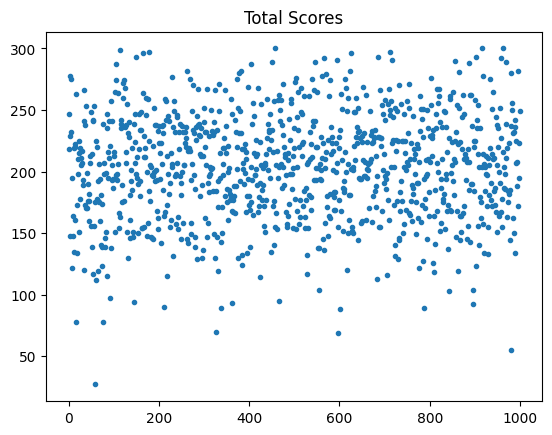

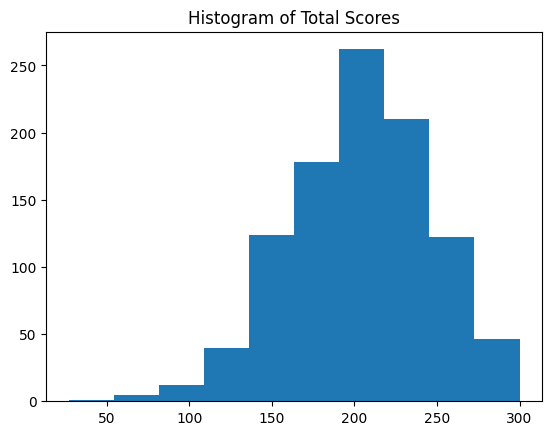

In [8]:
ts_scores = np.array(df['total score'])
plt.plot(ts_scores, '.')
plt.title('Total Scores')
plt.show()

plt.hist(ts_scores)
plt.title('Histogram of Total Scores')
plt.show()

In [9]:
def check_normality(data: np.ndarray, show_flag: bool=True) -> List[float]:
    """Check if the distribution is normal

    Parameters
    ----------
    data : vector of data to be tested
    show_flag : controls the display of data

    Returns
    -------
    ps : List of p-values for different normality tests
    """

    few_data = data[::10]

    # --- >>> START stats <<< ---
    # Graphical test: if the data lie on a line, they are pretty much
    # normally distributed
    if show_flag:
        _ = stats.probplot(data, plot=plt)
        plt.show()

    pVals = pd.Series()
    pFewVals = pd.Series()
    # The scipy normaltest is based on D-Agostino and Pearsons test that
    # combines skew and kurtosis to produce an omnibus test of normality.
    _, pVals['Omnibus']    = stats.normaltest(data)
    _, pFewVals['Omnibus'] = stats.normaltest(few_data)

    # Shapiro-Wilk test
    _, pVals['Shapiro-Wilk']    = stats.shapiro(data)
    _, pFewVals['Shapiro-Wilk'] = stats.shapiro(few_data)

    # Or you can check for normality with Lilliefors-test
    _, pVals['Lilliefors']    = lilliefors(data)
    _, pFewVals['Lilliefors'] = lilliefors(few_data)

    # Alternatively with original Kolmogorov-Smirnov test
    _, pVals['Kolmogorov-Smirnov']    = \
            stats.kstest((data-np.mean(data))/np.std(data,ddof=1), 'norm')
    _, pFewVals['Kolmogorov-Smirnov'] = \
        stats.kstest((few_data-np.mean(few_data))/np.std(few_data,ddof=1), 'norm')

    print(f'p-values for all {len(data)} data points: ----------------')
    print(pVals)
    print('p-values for the first 100 data points: ----------------')
    print(pFewVals)

    if pVals['Omnibus'] > 0.05:
        print('Data are normally distributed')
    # --- >>> STOP stats <<< ---

    return pVals



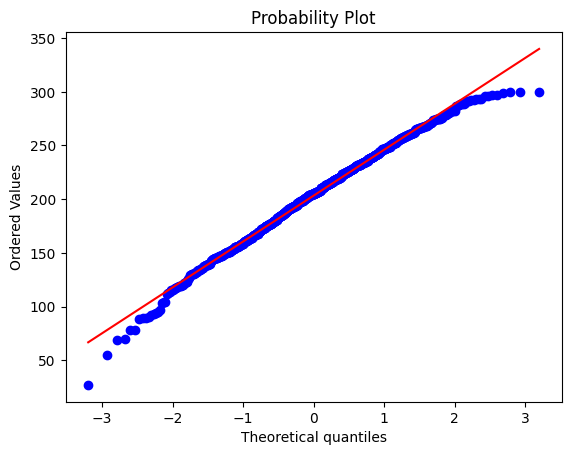

p-values for all 1000 data points: ----------------
Omnibus               0.000504
Shapiro-Wilk          0.000145
Lilliefors            0.021505
Kolmogorov-Smirnov    0.238855
dtype: float64
p-values for the first 100 data points: ----------------
Omnibus               0.006956
Shapiro-Wilk          0.043381
Lilliefors            0.115374
Kolmogorov-Smirnov    0.508650
dtype: float64


,0
Omnibus,0.000504
Shapiro-Wilk,0.000145
Lilliefors,0.021505
Kolmogorov-Smirnov,0.238855


In [10]:
check_normality(ts_scores, show_flag=True)

For all 1,000 observations, the Omnibus, Shapiro-Wilk, and Lilliefors tests had p-values below 0.05, but the Kolmogorov-Smirnov test had a p-value above 0.05. Since most of the tests reject the null hypothesis of normality, the total score distribution is treated as not normally distributed. So we move to the non-parametric tests.

In [11]:
#create data group for males who complete the test
male_completed = df[
    (df['gender'] == 'male') &
    (df['test preparation course'] == 'completed')
]

male_completed = np.array(male_completed['total score'])

In [12]:
np.mean(male_completed)

np.float64(212.3448275862069)

Male students who completed the test preparation course had about 17 points higher mean total score than students who did not complete the course.

In [13]:
#create data group for tudents who did not complete the test preparation course
none = df[
    df['test preparation course'] == 'none'
]

none = np.array(none['total score'])

In [14]:
np.mean(none)

np.float64(195.11682242990653)

Male students who completed the test preparation course had about 17 points higher mean total score than students who did not complete the course.

H0: There is no statistically significant difference in total scores between male students who completed the test preparation course and students who did not complete the course.

H1: There is a statistically significant difference in total scores between male students who completed the test preparation course and students who did not complete the course.

In [15]:
t_stat, p_value = stats.ttest_ind(male_completed, none)

print('t-statistic =', format(t_stat, '.2f'))
print('The p_value =', format(p_value, '.6f'))

t-statistic = 4.81
The p_value = 0.000002


In [16]:
statistic, p_value = stats.kruskal(male_completed, none)

print('Test statistic =', format(statistic, '.2f'))
print('The p_value =', format(p_value, '.6f'))

Test statistic = 21.50
The p_value = 0.000004


In [17]:
statistic, p_value = stats.mannwhitneyu(male_completed, none)

print('Test statistic =', format(statistic, '.2f'))
print('The p_value =', format(p_value, '.6f'))

Test statistic = 68639.50
The p_value = 0.000004


Male students who completed the test preparation course had a higher mean total score than students who did not complete the course. The independent-samples t-test produced a t-statistic of approximately 4.81 and a p-value below 0.05. Therefore, the null hypothesis is rejected, indicating a statistically significant difference in total scores between the two groups.

Because the overall total score distribution did not meet the normality assumption, Kruskal-Wallis and Mann-Whitney U tests were also conducted as non-parametric checks. Both tests also produced p-values below 0.05, supporting the same conclusion.

Check interest difference in race/ethnicity

In [18]:
df.groupby('race/ethnicity')['total score'].mean()

,total score
race/ethnicity,
group A,188.977528
group B,196.405263
group C,201.394984
group D,207.538168
group E,218.257143


In [19]:
group_a = np.array(
    df[df['race/ethnicity'] == 'group A']['total score']
)

group_b = np.array(
    df[df['race/ethnicity'] == 'group B']['total score']
)

group_c = np.array(
    df[df['race/ethnicity'] == 'group C']['total score']
)

group_d = np.array(
    df[df['race/ethnicity'] == 'group D']['total score']
)

group_e = np.array(
    df[df['race/ethnicity'] == 'group E']['total score']
)

H0: There is no statistically significant difference in total scores across race/ethnicity groups.

H1: At least one race/ethnicity group differs significantly in total scores.

In [20]:
statistic, p_value = stats.kruskal(
    group_a,
    group_b,
    group_c,
    group_d,
    group_e
)

print('Test statistic =', format(statistic, '.2f'))
print('The p_value =', format(p_value, '.8f'))

Test statistic = 36.18
The p_value = 0.00000027


The Kruskal-Wallis test produced a test statistic of 36.18 and a p-value below 0.05. Therefore, the null hypothesis（H0） is rejected. This provides evidence of a statistically significant difference in total score distributions across the race/ethnicity groups. At least one race/ethnicity group from the 5 groups distinguised in the dataset differs significantly from the others.

The group means can only be used to describe which groups appear to have higher or lower scores.

The Kruskal-Wallis test alone does not identify which specific pairs of groups are significantly different. Further investigation on the groups needed to be conducted to make more conclusions, such as which group is different.